# Fase B — Limpieza y normalización de datos
**Proyecto 2 y 3 — Estadísticas delictivas de Colombia 2025 (DIJIN)** · Grupo 7 · R.A. 2 y 3

Este notebook toma los **8 reportes `.xlsx` crudos** de la Policía Nacional y construye el
conjunto de datos listo para modelar. El orden de los pasos importa, así que se respeta esta secuencia:

1. Diagnóstico (nulos, duplicados, texto, outliers) sobre los casos crudos.
2. Limpieza a nivel de caso (tipos, texto, nulos categóricos con **moda**).
3. Agregación a panel **municipio × mes** y construcción de variables numéricas con historial.
4. Outliers (IQR / Z-score) y decisión explícita.
5. **Partición 80/20 antes de cualquier estadístico aprendido** (para no filtrar información del conjunto de prueba).
6. Transformación logarítmica, nulos numéricos (**KNN**, elegido frente a media y mediana con un experimento de recuperación), codificación y escalado (`RobustScaler`), ajustados **solo con entrenamiento**.
7. Guardado en `entrega/datos_limpios.parquet`.

Se ejecuta de principio a fin con **Restart & Run All** (tarda ~1 minuto por la lectura de los Excel).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder, RobustScaler, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

RAIZ = Path.cwd().parent if Path.cwd().name == "entrega" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from utilidades_delitos import (  # noqa: E402
    ZANAHORIA_2026_ORDEN_EDAD,
    calcular_porcentajes,
    cargar_datos_crudos,
    construir_panel_mensual,
    construir_perfil_municipios,
)

CARPETA_DATOS = RAIZ / "datos"
CARPETA_ENTREGA = RAIZ / "entrega"
CARPETA_FIGURAS = RAIZ / "figuras"
CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)

SEMILLA = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.3f}".format

## 1. Extracción y diagnóstico de los datos crudos

In [2]:
zanahoria_2026_df_crudo = cargar_datos_crudos(CARPETA_DATOS)
print(f"Filas crudas: {len(zanahoria_2026_df_crudo):,}  |  columnas: {zanahoria_2026_df_crudo.shape[1]}")
zanahoria_2026_df_crudo.head(3)

Filas crudas: 480,131  |  columnas: 9


,ARMAS MEDIOS,DEPARTAMENTO,MUNICIPIO,FECHA HECHO,GENERO,AGRUPA_EDAD_PERSONA,CODIGO DANE,CANTIDAD,TIPO_DELITO
0,ARMA BLANCA / CORTOPUNZANTE,CUNDINAMARCA,Bogotá D.C. (CT),01/01/2025,MASCULINO,ADULTOS,"11,001,000.000",1.000,HOMICIDIO INTENCIONAL
1,ARMA BLANCA / CORTOPUNZANTE,CUNDINAMARCA,Bogotá D.C. (CT),01/01/2025,MASCULINO,ADULTOS,"11,001,000.000",1.000,HOMICIDIO INTENCIONAL
2,ARMA BLANCA / CORTOPUNZANTE,CUNDINAMARCA,Bogotá D.C. (CT),01/01/2025,MASCULINO,ADULTOS,"11,001,000.000",1.000,HOMICIDIO INTENCIONAL


### 1.1 Filas de pie de página
Cada Excel termina con créditos (fuente, elaboró, revisó, autorizó). Se reconocen porque **no tienen código DANE**.

In [3]:
es_pie = zanahoria_2026_df_crudo["CODIGO DANE"].isna()
print(f"Filas de pie de página: {es_pie.sum()}  ({es_pie.mean():.4%} del total)")
zanahoria_2026_df_crudo.loc[es_pie, "ARMAS MEDIOS"].str[:60].head(5).to_frame()

Filas de pie de página: 40  (0.0083% del total)


,ARMAS MEDIOS
13722,FUENTE: DIJIN-POLICÍA NACIO...
13723,*Agrupación referente a la clasificación del c...
13724,Elaboró: PP. NATALY TEPHANI QUIROZ LEDESMA
13725,Revisó: SI. IVAN MATEUS LARA
13726,Autorizó: MY. MIGUEL ANTONIO CIPAGAUTA DIAZ


### 1.2 Nulos: ¿son errores o ausencia estructural?
Se cruzan los nulos con el tipo de delito. Esto decide la estrategia: un nulo **estructural**
(la variable no existe para ese delito) no se imputa; un nulo **puntual** sí.

In [4]:
zanahoria_2026_df_sin_pie = zanahoria_2026_df_crudo.loc[~es_pie].copy()
tabla_nulos = (
    zanahoria_2026_df_sin_pie.groupby("TIPO_DELITO")[["GENERO", "AGRUPA_EDAD_PERSONA"]]
    .agg(lambda s: s.isna().mean() * 100)
    .round(2)
    .rename(columns={"GENERO": "% nulos GENERO", "AGRUPA_EDAD_PERSONA": "% nulos EDAD"})
)
tabla_nulos["filas"] = zanahoria_2026_df_sin_pie.groupby("TIPO_DELITO").size()
tabla_nulos

,% nulos GENERO,% nulos EDAD,filas
TIPO_DELITO,,,
HOMICIDIO INTENCIONAL,0.000,0.000,13722
HOMICIDIOS EN ACCIDENTE DE TRÁNSITO,0.760,0.530,7531
HURTO A PERSONAS,0.030,0.010,290886
HURTO A RESIDENCIAS,0.050,0.000,25631
HURTO PIRATERÍA TERRESTRE,100.000,100.000,100
SECUESTRO,0.000,0.000,651
TERRORISMO,100.000,100.000,209
VIOLENCIA INTRAFAMILIAR,0.710,0.370,141361


In [5]:
# Nulos en el resto de columnas (después de quitar el pie de página)
otras_cols = ["ARMAS MEDIOS", "DEPARTAMENTO", "MUNICIPIO", "FECHA HECHO", "CODIGO DANE", "CANTIDAD"]
nulos_otras = zanahoria_2026_df_sin_pie[otras_cols].isna().sum()
print(nulos_otras[nulos_otras > 0].to_dict())
zanahoria_2026_df_sin_pie.loc[zanahoria_2026_df_sin_pie["MUNICIPIO"].isna(), ["TIPO_DELITO", "DEPARTAMENTO", "MUNICIPIO", "FECHA HECHO", "CODIGO DANE"]]

{'MUNICIPIO': 2}

,TIPO_DELITO,DEPARTAMENTO,MUNICIPIO,FECHA HECHO,CODIGO DANE
237946,HURTO A PERSONAS,NARIÑO,NaN,09/06/2025,"52,000,000.000"
361160,VIOLENCIA INTRAFAMILIAR,NARIÑO,NaN,16/01/2025,"52,000,000.000"


Hay **2 casos sin nombre de municipio** pero con código DANE `52000000` (terminado en `000`, o sea un código
a nivel de departamento: Nariño). No es un nulo aleatorio sino un caso registrado sin municipio específico.

### 1.3 Duplicados
El grano de la fuente es **un caso**, y los archivos **no traen un identificador de caso**.
Hay que distinguir un duplicado "de error" de dos casos distintos que comparten todos sus atributos.

In [6]:
columnas_caso = ["ARMAS MEDIOS", "DEPARTAMENTO", "MUNICIPIO", "FECHA HECHO", "GENERO",
                 "AGRUPA_EDAD_PERSONA", "CODIGO DANE", "TIPO_DELITO"]
n_dup = zanahoria_2026_df_sin_pie.duplicated(columnas_caso).sum()
print(f"Filas idénticas en todos sus atributos: {n_dup:,} ({n_dup / len(zanahoria_2026_df_sin_pie):.1%})")
print("Valores de CANTIDAD:", zanahoria_2026_df_sin_pie["CANTIDAD"].value_counts().to_dict())

# Ejemplo concreto: la combinación repetida más frecuente
combinacion_top = (
    zanahoria_2026_df_sin_pie.groupby(columnas_caso, dropna=False).size().sort_values(ascending=False).head(3)
    .rename("veces repetida").reset_index()
)
combinacion_top[["TIPO_DELITO", "MUNICIPIO", "FECHA HECHO", "ARMAS MEDIOS", "GENERO", "veces repetida"]]

Filas idénticas en todos sus atributos: 301,560 (62.8%)
Valores de CANTIDAD: {1.0: 480091}


,TIPO_DELITO,MUNICIPIO,FECHA HECHO,ARMAS MEDIOS,GENERO,veces repetida
0,HURTO A PERSONAS,Bogotá D.C. (CT),17/10/2025,SIN EMPLEO DE ARMAS,MASCULINO,223
1,HURTO A PERSONAS,Bogotá D.C. (CT),04/10/2025,SIN EMPLEO DE ARMAS,MASCULINO,221
2,HURTO A PERSONAS,Bogotá D.C. (CT),24/10/2025,SIN EMPLEO DE ARMAS,MASCULINO,218


### 1.4 Inconsistencias de texto

In [7]:
mun = zanahoria_2026_df_sin_pie["MUNICIPIO"].astype(str)
print("Municipios con sufijo '(CT)':", f"{mun.str.contains(r'\(CT\)').sum():,} filas")
print("Municipios no escritos en MAYÚSCULAS:", f"{(mun != mun.str.upper()).sum():,} filas")

# El mismo nombre de municipio aparece con más de un código DANE (centros poblados del mismo municipio y homónimos entre departamentos)
codigos_por_nombre = zanahoria_2026_df_sin_pie.groupby("MUNICIPIO")["CODIGO DANE"].nunique()
print("Nombres de municipio con más de un código DANE:", (codigos_por_nombre > 1).sum())
print("Ejemplo:", codigos_por_nombre.sort_values(ascending=False).head(3).to_dict())

# Y cada código DANE tiene un único nombre: el código es la llave confiable
nombres_por_codigo = zanahoria_2026_df_sin_pie.groupby("CODIGO DANE")["MUNICIPIO"].nunique()
print("Códigos DANE con más de un nombre:", (nombres_por_codigo > 1).sum())

Municipios con sufijo '(CT)': 346,573 filas
Municipios no escritos en MAYÚSCULAS: 480,091 filas
Nombres de municipio con más de un código DANE: 291
Ejemplo: {'Valledupar (CT)': 15, 'Leticia (CT)': 9, 'Ibagué (CT)': 7}
Códigos DANE con más de un nombre: 0


In [8]:
armas = zanahoria_2026_df_sin_pie["ARMAS MEDIOS"].value_counts()
print(f"Categorías de ARMAS MEDIOS: {len(armas)}")
print(f"Categorías con < 0.1% de los casos: {(armas / armas.sum() < 0.001).sum()}")
armas.tail(8).to_frame("casos")

Categorías de ARMAS MEDIOS: 23
Categorías con < 0.1% de los casos: 13


,casos
ARMAS MEDIOS,
MOTO BOMBA,9
CILINDRO BOMBA,5
MEDIOS DE COMUNICACIÓN Y REDES SOCIALES AFTER SCHOOL,4
MINA ANTIPERSONA,3
PETARDO PLANFETARIO,3
ARTEFACTO INCENDIARIO,2
BICICLETA BOMBA,1
GRANADA DE FUSIL,1


In [9]:
cruce_no_rep = (
    zanahoria_2026_df_sin_pie.assign(no_rep=zanahoria_2026_df_sin_pie["ARMAS MEDIOS"].eq("NO REPORTADO"))
    .groupby("TIPO_DELITO")["no_rep"].mean().mul(100).round(1).rename("% 'NO REPORTADO' en ARMAS")
)
cruce_no_rep

TIPO_DELITO
HOMICIDIO INTENCIONAL                  0.000
HOMICIDIOS EN ACCIDENTE DE TRÁNSITO   60.100
HURTO A PERSONAS                       3.100
HURTO A RESIDENCIAS                    1.300
HURTO PIRATERÍA TERRESTRE              6.000
SECUESTRO                              0.000
TERRORISMO                             0.000
VIOLENCIA INTRAFAMILIAR                0.000
Name: % 'NO REPORTADO' en ARMAS, dtype: float64

**Hallazgos del diagnóstico** (cada uno se resuelve en la sección 2):

| Problema | Magnitud | Decisión |
|---|---|---|
| Filas de pie de página | 40 filas | Eliminar |
| Nulos en `GENERO` / `EDAD` | Estructurales en Terrorismo y Piratería (100 %); puntuales (<1 %) en el resto | Estructurales: no imputar. Puntuales: **moda** por tipo de delito |
| `MUNICIPIO` nulo | 2 casos, código DANE de nivel departamental (Nariño) | Etiquetar `SIN ESPECIFICAR (NARIÑO)`; una moda no tiene sentido en un identificador geográfico |
| Filas idénticas | ~63 % del total | **Conservar**: son casos distintos (la fuente no trae ID de caso y `CANTIDAD` = 1 siempre) |
| Municipio en minúscula y con `(CT)` | 346 mil filas con sufijo | Normalizar a MAYÚSCULAS sin sufijo; **la llave es el código DANE**, no el nombre |
| `NO REPORTADO` en armas | 60 % en homicidios de tránsito | Conservar como categoría propia: no es un nulo sino "no aplica / no informado" |
| Categorías de arma casi vacías | Varias con < 0.1 % | Agrupar en `OTRO` |

## 2. Limpieza a nivel de caso

In [10]:
zanahoria_2026_df_casos = zanahoria_2026_df_sin_pie.copy()

# Tipos: fecha como fecha, código DANE como entero (es un código), cantidad como entero
zanahoria_2026_df_casos["fecha"] = pd.to_datetime(zanahoria_2026_df_casos["FECHA HECHO"], format="%d/%m/%Y")
zanahoria_2026_df_casos["dane"] = zanahoria_2026_df_casos["CODIGO DANE"].astype("int64")
zanahoria_2026_df_casos["cantidad"] = zanahoria_2026_df_casos["CANTIDAD"].astype(int)
assert zanahoria_2026_df_casos["fecha"].dt.year.eq(2025).all(), "hay fechas fuera de 2025"

# Texto: mayúsculas, sin espacios sobrantes y sin el sufijo administrativo '(CT)'
zanahoria_2026_df_casos["departamento"] = zanahoria_2026_df_casos["DEPARTAMENTO"].str.strip().str.upper()
zanahoria_2026_df_casos["municipio"] = (
    zanahoria_2026_df_casos["MUNICIPIO"].str.replace(r"\s*\(CT\)", "", regex=True).str.strip().str.upper()
)
zanahoria_2026_df_casos["tipo_delito"] = zanahoria_2026_df_casos["TIPO_DELITO"].str.strip().str.upper()

# Los 2 casos sin municipio se conservan con una etiqueta explícita (sigue siendo un caso real de Nariño)
sin_municipio = zanahoria_2026_df_casos["municipio"].isna()
zanahoria_2026_df_casos.loc[sin_municipio, "municipio"] = "SIN ESPECIFICAR (" + zanahoria_2026_df_casos.loc[sin_municipio, "departamento"] + ")"
assert zanahoria_2026_df_casos["municipio"].notna().all()

# Armas: se agrupan las categorías raras (< 0.1 %) en OTRO; 'NO REPORTADO' se conserva
frecuencia_arma = zanahoria_2026_df_casos["ARMAS MEDIOS"].value_counts(normalize=True)
raras = frecuencia_arma[frecuencia_arma < 0.001].index
zanahoria_2026_df_casos["arma_grupo"] = zanahoria_2026_df_casos["ARMAS MEDIOS"].replace(dict.fromkeys(raras, "OTRO"))
print("Categorías de arma después de agrupar:", zanahoria_2026_df_casos["arma_grupo"].nunique())

zanahoria_2026_df_casos["genero"] = zanahoria_2026_df_casos["GENERO"]
zanahoria_2026_df_casos["edad"] = zanahoria_2026_df_casos["AGRUPA_EDAD_PERSONA"]
zanahoria_2026_df_casos[["tipo_delito", "departamento", "municipio", "arma_grupo"]].nunique().to_frame("valores únicos")

Categorías de arma después de agrupar: 11


,valores únicos
tipo_delito,8
departamento,32
municipio,1018
arma_grupo,11


### 2.1 Estrategia 1 para nulos — **MODA** (variables categóricas)
`GENERO` y `EDAD` son categóricas, así que media y mediana no aplican. Para los nulos **puntuales**
se usa la **moda dentro de cada tipo de delito** (la moda global estaría sesgada por Hurto a personas,
que pesa el 60 %: asignaría "MASCULINO" a víctimas de violencia intrafamiliar, donde predomina lo femenino).
Los nulos **estructurales** (Terrorismo y Piratería) **no se imputan**: inventar el género de una víctima
que la fuente nunca registró distorsionaría los porcentajes.

In [11]:
estructural = zanahoria_2026_df_casos["tipo_delito"].isin(["TERRORISMO", "HURTO PIRATERÍA TERRESTRE"])
puntual_genero = zanahoria_2026_df_casos["genero"].isna() & ~estructural
puntual_edad = zanahoria_2026_df_casos["edad"].isna() & ~estructural
print(f"Nulos puntuales a imputar -> GENERO: {puntual_genero.sum():,} | EDAD: {puntual_edad.sum():,}")

moda_por_delito = (
    zanahoria_2026_df_casos.loc[~estructural]
    .groupby("tipo_delito")[["genero", "edad"]]
    .agg(lambda s: s.mode().iat[0])
)
# La moda debe ser estable: se muestra qué tan dominante es en cada tipo de delito
dominancia = (
    zanahoria_2026_df_casos.loc[~estructural]
    .groupby("tipo_delito")["genero"].agg(lambda s: s.value_counts(normalize=True).iloc[0]).rename("peso de la moda (género)")
)
display(moda_por_delito.join(dominancia))

for col in ["genero", "edad"]:
    relleno = zanahoria_2026_df_casos["tipo_delito"].map(moda_por_delito[col])
    zanahoria_2026_df_casos[col] = zanahoria_2026_df_casos[col].fillna(relleno.where(~estructural))

print("\nNulos restantes (solo estructurales):")
print(zanahoria_2026_df_casos[["genero", "edad"]].isna().sum().to_dict())

Nulos puntuales a imputar -> GENERO: 1,168 | EDAD: 577


,genero,edad,peso de la moda (género)
tipo_delito,,,
HOMICIDIO INTENCIONAL,MASCULINO,ADULTOS,0.926
HOMICIDIOS EN ACCIDENTE DE TRÁNSITO,MASCULINO,ADULTOS,0.795
HURTO A PERSONAS,MASCULINO,ADULTOS,0.564
HURTO A RESIDENCIAS,MASCULINO,ADULTOS,0.557
SECUESTRO,MASCULINO,ADULTOS,0.876
VIOLENCIA INTRAFAMILIAR,FEMENINO,ADULTOS,0.746



Nulos restantes (solo estructurales):
{'genero': 309, 'edad': 309}


### 2.2 Codificación **ordinal** de la edad de la víctima
`MENORES < ADOLESCENTES < ADULTOS` tiene un orden natural, por lo que se codifica con
`OrdinalEncoder` con el orden explícito (0, 1, 2). Un One-Hot perdería ese orden.

In [12]:
codificador_edad = OrdinalEncoder(categories=[ZANAHORIA_2026_ORDEN_EDAD], handle_unknown="use_encoded_value", unknown_value=np.nan)
zanahoria_2026_df_casos["edad_ord"] = codificador_edad.fit_transform(zanahoria_2026_df_casos[["edad"]]).ravel()
zanahoria_2026_df_casos.groupby("edad", dropna=False)["edad_ord"].agg(["first", "size"])

,first,size
edad,,
ADOLESCENTES,1.000,9141
ADULTOS,2.000,462319
MENORES,0.000,8322
NaN,NaN,309


### 2.3 Validación del resultado a nivel de caso

In [13]:
assert len(zanahoria_2026_df_casos) == 480_091, "el total de casos no coincide con el del Proyecto 1"
print(f"Casos limpios: {len(zanahoria_2026_df_casos):,} (idéntico al consolidado del Proyecto 1)")
print("Códigos DANE:", zanahoria_2026_df_casos["dane"].nunique(), "| Departamentos:", zanahoria_2026_df_casos["departamento"].nunique())

Casos limpios: 480,091 (idéntico al consolidado del Proyecto 1)
Códigos DANE: 1500 | Departamentos: 32


## 3. Del caso al panel municipio × mes

Con una fila por caso, la única columna numérica (`CANTIDAD`) es constante, así que no hay nada que
normalizar ni escalar. Se **agrega a municipio × mes** (1 500 unidades territoriales DANE × 12 meses = 18 000 filas;
la ausencia de casos se registra como 0, que es un valor real) y se construyen variables numéricas.

**Unidad territorial.** El código DANE de la DIJIN tiene 8 dígitos: 5 del municipio y 3 del centro poblado.
Las 1 500 unidades son 1 105 cabeceras municipales (sufijo `000`) y 395 centros poblados (corregimientos e
inspecciones) de 1 106 municipios; los centros poblados reúnen solo 1 264 casos (0,26 %). Por brevedad, en los
notebooks se les llama "municipios".

**Pregunta de negocio que guía el modelado:** *¿cuántos casos delictivos registrará un municipio el próximo mes?*
(es la "proyección de casos por mes" que el Proyecto 1 dejó como próximo paso).

Para que sea una predicción real y no una identidad, **las variables explicativas usan solo información
de meses anteriores** (`lag1` = mes anterior; `acum` = acumulado hasta el mes anterior).

In [14]:
zanahoria_2026_panel = construir_panel_mensual(zanahoria_2026_df_casos)
assert zanahoria_2026_panel["casos"].sum() == len(zanahoria_2026_df_casos), "el panel perdió o duplicó casos"
print("Panel:", zanahoria_2026_panel.shape, "| suma de casos:", f"{zanahoria_2026_panel['casos'].sum():,}")
print(f"Celdas municipio-mes sin casos: {(zanahoria_2026_panel['casos'] == 0).mean():.1%}")

Panel: (18000, 17) | suma de casos: 480,091
Celdas municipio-mes sin casos: 37.0%


In [15]:
p = zanahoria_2026_panel.sort_values(["dane", "mes"]).reset_index(drop=True)
g = p.groupby("dane")

sumas = ["casos", "casos_hurto", "casos_vif", "casos_homicidio", "casos_otros", "fin_sem",
         "tiene_genero", "es_fem", "tiene_edad", "edad_ord", "es_fuego", "es_sin_arma"]

# Acumulado HASTA el mes anterior (cumsum menos el mes actual): nunca incluye el mes que se predice
acum = g[sumas].cumsum() - p[sumas]

# Valores del mes anterior (lag 1)
cols_lag = ["casos", "casos_hurto", "casos_vif", "casos_homicidio", "casos_otros", "dias_activos"]
lag1 = g[cols_lag].shift(1).add_suffix("_lag1")

zanahoria_2026_df_feat = pd.concat(
    [
        p[["dane", "departamento", "municipio", "mes"]],
        lag1,
        acum[["casos"]].rename(columns={"casos": "casos_acum_prev"}),
        calcular_porcentajes(acum, "_acum"),
    ],
    axis=1,
)
# Meses con casos hasta el mes anterior
zanahoria_2026_df_feat["meses_con_casos_prev"] = g["casos"].transform(lambda s: (s > 0).cumsum()) - (p["casos"] > 0)

# Perfil dominante del mes anterior (variable NOMINAL -> One-Hot más adelante)
fam_lag = lag1[["casos_hurto_lag1", "casos_vif_lag1", "casos_homicidio_lag1", "casos_otros_lag1"]]
dominante = fam_lag.fillna(0).idxmax(axis=1).str.replace("casos_", "").str.replace("_lag1", "").str.upper()
zanahoria_2026_df_feat["perfil_dominante_lag1"] = dominante.where(fam_lag.fillna(0).sum(axis=1) > 0, "SIN_CASOS")

# Variable objetivo: casos del mes (se descarta enero: no tiene mes anterior)
zanahoria_2026_df_feat["casos"] = p["casos"]
zanahoria_2026_df_feat = zanahoria_2026_df_feat.loc[zanahoria_2026_df_feat["mes"] >= 2].reset_index(drop=True)
# Indicador: el municipio no tenía ningún caso registrado antes de este mes (regla fija, no aprende nada)
zanahoria_2026_df_feat["sin_historial_previo"] = zanahoria_2026_df_feat["casos_acum_prev"].eq(0).astype("int8")
zanahoria_2026_df_feat["mes_num"] = zanahoria_2026_df_feat["mes"]
print("Filas para modelar (feb-dic):", zanahoria_2026_df_feat.shape)
zanahoria_2026_df_feat.head(3)

Filas para modelar (feb-dic): (16500, 21)


,dane,departamento,municipio,mes,casos_lag1,casos_hurto_lag1,casos_vif_lag1,casos_homicidio_lag1,casos_otros_lag1,dias_activos_lag1,...,pct_fin_semana_acum,pct_femenina_acum,edad_ordinal_media_acum,pct_arma_fuego_acum,pct_sin_armas_acum,meses_con_casos_prev,perfil_dominante_lag1,casos,sin_historial_previo,mes_num
0,5001000,ANTIOQUIA,MEDELLÍN,2,"2,613.000","1,746.000",800.000,65.000,2.000,31.000,...,0.250,0.482,1.944,0.111,0.514,1,HURTO,2743,0,2
1,5001000,ANTIOQUIA,MEDELLÍN,3,"2,743.000","1,915.000",775.000,53.000,0.000,28.000,...,0.266,0.485,1.950,0.104,0.544,2,HURTO,3222,0,3
2,5001000,ANTIOQUIA,MEDELLÍN,4,"3,222.000","2,189.000",937.000,95.000,1.000,31.000,...,0.289,0.490,1.951,0.106,0.548,3,HURTO,2786,0,4


**Validaciones de coherencia del panel** (valores imposibles y fugas):

In [16]:
pcts = [c for c in zanahoria_2026_df_feat.columns if c.startswith("pct_")]
assert (zanahoria_2026_df_feat[pcts].dropna().apply(lambda s: s.between(0, 1).all())).all(), "porcentaje fuera de [0,1]"
assert (zanahoria_2026_df_feat["edad_ordinal_media_acum"].dropna().between(0, 2)).all()
assert (zanahoria_2026_df_feat["casos"] >= 0).all()

# Verificación anti-fuga: el acumulado de un municipio en el mes t más lo ocurrido en t es el acumulado de t+1
ej = p[p["dane"] == p["dane"].iloc[0]].reset_index(drop=True)
a = g[["casos"]].cumsum() - p[["casos"]]
a_ej = a[p["dane"] == ej["dane"].iloc[0]].reset_index(drop=True)["casos"]
assert (a_ej.iloc[1:].values == (a_ej + ej["casos"]).iloc[:-1].values).all()
print("Sin valores imposibles y sin fuga temporal en las variables acumuladas.")

Sin valores imposibles y sin fuga temporal en las variables acumuladas.


## 4. Valores atípicos (IQR y Z-score)

In [17]:
cols_conteo = ["casos", "casos_lag1", "casos_hurto_lag1", "casos_vif_lag1", "casos_acum_prev"]

def resumir_atipicos(df: pd.DataFrame, columnas: list[str]) -> pd.DataFrame:
    """ZANAHORIA_2026: cuenta atípicos por IQR (1.5 x IQR) y por Z-score (|z| > 3) para cada columna."""
    filas = []
    for col in columnas:
        s = df[col].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        fuera_iqr = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()
        fuera_z = (np.abs(stats.zscore(s)) > 3).mean()
        filas.append({"variable": col, "mediana": s.median(), "máximo": s.max(), "% atípicos IQR": fuera_iqr * 100,
                      "% atípicos Z>3": fuera_z * 100, "asimetría": s.skew()})
    return pd.DataFrame(filas).set_index("variable")

zanahoria_2026_tabla_out = resumir_atipicos(zanahoria_2026_df_feat, cols_conteo)
zanahoria_2026_tabla_out

,mediana,máximo,% atípicos IQR,% atípicos Z>3,asimetría
variable,,,,,
casos,1.000,"18,567.000",12.576,0.236,36.251
casos_lag1,1.000,"18,567.000",10.582,0.230,35.604
casos_hurto_lag1,0.000,"13,323.000",13.527,0.242,35.921
casos_vif_lag1,0.000,"5,484.000",12.248,0.200,36.365
casos_acum_prev,7.000,"172,368.000",12.691,0.194,44.868


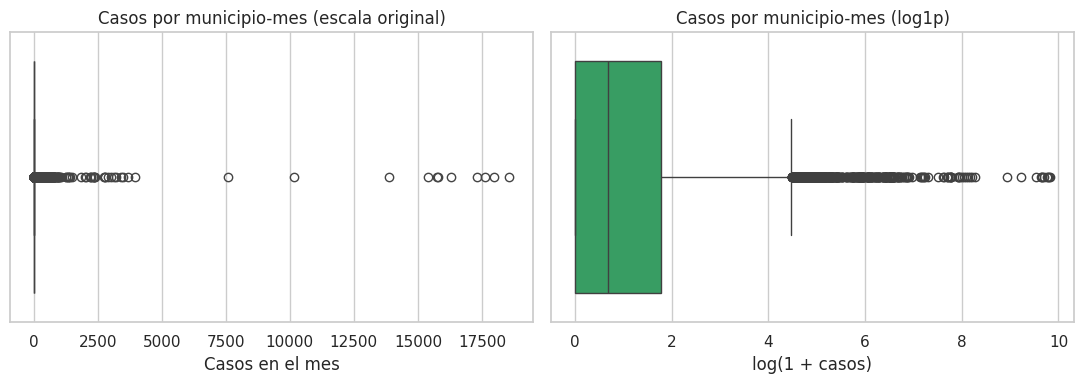

In [18]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=zanahoria_2026_df_feat["casos"], ax=ejes[0], color="#2980b9")
ejes[0].set_title("Casos por municipio-mes (escala original)")
ejes[0].set_xlabel("Casos en el mes")
sns.boxplot(x=np.log1p(zanahoria_2026_df_feat["casos"]), ax=ejes[1], color="#27ae60")
ejes[1].set_title("Casos por municipio-mes (log1p)")
ejes[1].set_xlabel("log(1 + casos)")
plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "zanahoria_2026_boxplot_outliers_b.png", dpi=130)
plt.show()

In [19]:
top = (zanahoria_2026_df_feat.groupby(["municipio", "departamento"])["casos"].max().sort_values(ascending=False).head(6))
print("Máximos mensuales (los 'atípicos' extremos):")
top.to_frame("casos en su mes pico")

Máximos mensuales (los 'atípicos' extremos):


,,casos en su mes pico
municipio,departamento,
BOGOTÁ D.C.,CUNDINAMARCA,18567
MEDELLÍN,ANTIOQUIA,3938
CALI,VALLE,2402
BARRANQUILLA,ATLÁNTICO,1480
CARTAGENA,BOLÍVAR,1007
SOACHA,CUNDINAMARCA,959


### Decisión sobre los atípicos: **se conservan**
Más del 10 % de las filas son "atípicas" por IQR, pero los extremos corresponden a Bogotá, Medellín, Cali,
Barranquilla y otras capitales: **son reales**, no errores de captura (el diagnóstico confirmó 0 valores
imposibles). Eliminarlos descartaría precisamente los municipios donde se concentra el delito y haría que
el modelo fallara donde más importa. En lugar de borrarlos:
* se **transforma con log1p** para comprimir la cola (sección 6);
* se escala con **RobustScaler** (mediana e IQR), que no se deja arrastrar por los extremos;
* se deja una marca `atipico_iqr` en el parquet para poder auditarlos después.

## 5. Partición entrenamiento / prueba (80/20) — **antes** de aprender cualquier estadístico

A partir de aquí, toda transformación que *aprende* algo de los datos (asimetría usada para decidir el log,
valores de imputación, vecinos de KNN, mediana e IQR del escalador, cortes de atípicos) se ajusta **solo con
las filas de entrenamiento** y luego se aplica a todas. Así ninguna fila de prueba influye en las
transformaciones: el enunciado prohíbe normalizar antes del split (data leakage).

In [20]:
indices = zanahoria_2026_df_feat.index
idx_train, idx_test = train_test_split(indices, test_size=0.20, random_state=SEMILLA)
zanahoria_2026_df_feat["particion"] = np.where(zanahoria_2026_df_feat.index.isin(idx_train), "train", "test")
print(zanahoria_2026_df_feat["particion"].value_counts().to_dict())

entrena = zanahoria_2026_df_feat["particion"].eq("train")

# Marca de atípicos con los cortes calculados SOLO en entrenamiento
q1, q3 = zanahoria_2026_df_feat.loc[entrena, "casos"].quantile([0.25, 0.75])
corte_alto = q3 + 1.5 * (q3 - q1)
zanahoria_2026_df_feat["atipico_iqr"] = (zanahoria_2026_df_feat["casos"] > corte_alto).astype("int8")
print(f"Corte IQR (train): {corte_alto:.1f} casos/mes -> {zanahoria_2026_df_feat['atipico_iqr'].mean():.1%} de las filas marcadas")

{'train': 13200, 'test': 3300}
Corte IQR (train): 12.5 casos/mes -> 12.6% de las filas marcadas


## 6. Transformación y limpieza numérica (ajustadas en entrenamiento)

### 6.1 Transformación logarítmica
Se aplica `log1p` a las variables de conteo con **asimetría > 1** medida en entrenamiento.
Se usa `log1p` (y no Box-Cox) porque hay ceros reales, que Box-Cox no admite; además es fácil de interpretar y de revertir.

In [21]:
conteos = ["casos_lag1", "casos_hurto_lag1", "casos_vif_lag1", "casos_homicidio_lag1", "casos_otros_lag1",
           "dias_activos_lag1", "casos_acum_prev", "meses_con_casos_prev"]
asimetria_antes = zanahoria_2026_df_feat.loc[entrena, conteos].skew()
a_log = asimetria_antes[asimetria_antes > 1].index.tolist()
print("Variables con asimetría > 1 (se transforman):", a_log)
print("No se transforman:", [c for c in conteos if c not in a_log])

zanahoria_2026_df_trans = zanahoria_2026_df_feat.copy()
for col in a_log:
    zanahoria_2026_df_trans[col + "_log"] = np.log1p(zanahoria_2026_df_trans[col])
zanahoria_2026_df_trans = zanahoria_2026_df_trans.drop(columns=a_log)

# La variable objetivo también se modela en escala log (se conserva la original)
zanahoria_2026_df_trans["y_log1p"] = np.log1p(zanahoria_2026_df_trans["casos"])

asimetria_despues = zanahoria_2026_df_trans.loc[entrena, [c + "_log" for c in a_log]].skew()
comparativo = pd.DataFrame({"antes": asimetria_antes[a_log].values, "después (log1p)": asimetria_despues.values}, index=a_log)
comparativo

Variables con asimetría > 1 (se transforman): ['casos_lag1', 'casos_hurto_lag1', 'casos_vif_lag1', 'casos_homicidio_lag1', 'casos_otros_lag1', 'dias_activos_lag1', 'casos_acum_prev']
No se transforman: ['meses_con_casos_prev']


,antes,después (log1p)
casos_lag1,44.184,1.498
casos_hurto_lag1,44.341,2.260
casos_vif_lag1,45.679,1.914
casos_homicidio_lag1,16.405,2.276
casos_otros_lag1,61.384,10.880
dias_activos_lag1,2.484,0.709
casos_acum_prev,55.048,0.822


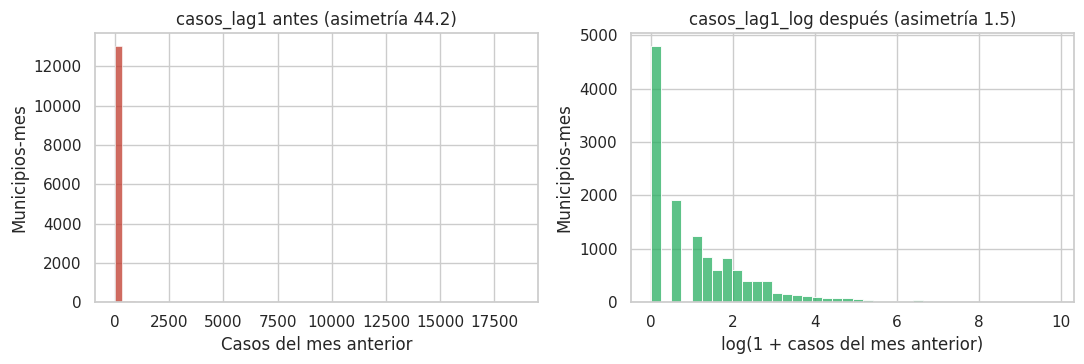

In [22]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(zanahoria_2026_df_feat.loc[entrena, "casos_lag1"], bins=60, ax=ejes[0], color="#c0392b")
ejes[0].set(title="casos_lag1 antes (asimetría %.1f)" % asimetria_antes["casos_lag1"], xlabel="Casos del mes anterior", ylabel="Municipios-mes")
sns.histplot(zanahoria_2026_df_trans.loc[entrena, "casos_lag1_log"], bins=40, ax=ejes[1], color="#27ae60")
ejes[1].set(title="casos_lag1_log después (asimetría %.1f)" % asimetria_despues["casos_lag1_log"], xlabel="log(1 + casos del mes anterior)", ylabel="Municipios-mes")
plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "zanahoria_2026_log_antes_despues.png", dpi=130)
plt.show()

### 6.2 Estrategia 2 para nulos — variables **numéricas** (media vs. mediana vs. KNN)
Los porcentajes acumulados (`pct_*_acum`, `edad_ordinal_media_acum`) quedan en `NaN` cuando el municipio
**no había tenido ningún caso antes** (no hay base para calcular un porcentaje). Se marca primero con un
indicador (`sin_historial_previo`, creado en la sección 3) —porque que un municipio no tenga historial es información por sí misma—
y luego se decide cómo rellenar con un **experimento**: se esconden al azar valores conocidos de
entrenamiento y se mide qué método los recupera con menos error.

In [23]:
cols_pct = ["pct_fin_semana_acum", "pct_femenina_acum", "edad_ordinal_media_acum", "pct_arma_fuego_acum", "pct_sin_armas_acum"]
cols_num = [c for c in zanahoria_2026_df_trans.columns
            if c.endswith("_log") and c != "y_log1p"] + cols_pct + ["meses_con_casos_prev", "mes_num"]   # meses_con_casos_prev no necesitó log, pero sí escalado
print("Nulos por columna numérica (todo el panel):")
zanahoria_2026_df_trans[cols_num].isna().sum()[lambda s: s > 0].to_frame("nulos")

Nulos por columna numérica (todo el panel):


,nulos
pct_fin_semana_acum,2043
pct_femenina_acum,2043
edad_ordinal_media_acum,2043
pct_arma_fuego_acum,2043
pct_sin_armas_acum,2043


In [24]:
# El escalador se ajusta en entrenamiento; el experimento de imputación se hace en el espacio escalado
escalador = RobustScaler().fit(zanahoria_2026_df_trans.loc[entrena, cols_num])
X_tr = pd.DataFrame(escalador.transform(zanahoria_2026_df_trans.loc[entrena, cols_num]), columns=cols_num)

completas = X_tr.dropna().index
rng = np.random.default_rng(SEMILLA)
mascara = pd.DataFrame(False, index=X_tr.index, columns=cols_num)
for col in cols_pct:
    elegidas = rng.choice(completas, size=int(0.15 * len(completas)), replace=False)
    mascara.loc[elegidas, col] = True

X_oculto = X_tr.mask(mascara)
resultados = {}
for nombre, imputador in {
    "Media": SimpleImputer(strategy="mean"),
    "Mediana": SimpleImputer(strategy="median"),
    "KNN (k=5)": KNNImputer(n_neighbors=5),
}.items():
    X_imp = pd.DataFrame(imputador.fit_transform(X_oculto), columns=cols_num, index=X_tr.index)
    error = (X_imp[cols_pct] - X_tr[cols_pct]).where(mascara[cols_pct]).abs()
    resultados[nombre] = error.mean()
zanahoria_2026_df_imp_mae = pd.DataFrame(resultados)

# El MAE crudo engaña: edad_ordinal_media casi no varía (IQR minúsculo) y domina el promedio en escala robusta.
# Por eso se compara cada variable contra la media (1.00 = igual que la media; menos de 1 = mejor) y se promedia.
zanahoria_2026_df_imp_rel = zanahoria_2026_df_imp_mae.div(zanahoria_2026_df_imp_mae["Media"], axis=0)
zanahoria_2026_df_imp_rel.loc["PROMEDIO RELATIVO"] = zanahoria_2026_df_imp_rel.mean()
print("MAE por variable (escala RobustScaler):")
display(zanahoria_2026_df_imp_mae)
print("MAE relativo a la media:")
zanahoria_2026_df_imp_rel

MAE por variable (escala RobustScaler):


,Media,Mediana,KNN (k=5)
pct_fin_semana_acum,0.768,0.760,0.749
pct_femenina_acum,0.689,0.685,0.597
edad_ordinal_media_acum,1.603,1.249,1.564
pct_arma_fuego_acum,0.791,0.690,0.575
pct_sin_armas_acum,0.642,0.639,0.497


MAE relativo a la media:


,Media,Mediana,KNN (k=5)
pct_fin_semana_acum,1.000,0.990,0.976
pct_femenina_acum,1.000,0.994,0.866
edad_ordinal_media_acum,1.000,0.779,0.976
pct_arma_fuego_acum,1.000,0.873,0.727
pct_sin_armas_acum,1.000,0.996,0.774
PROMEDIO RELATIVO,1.000,0.926,0.864


Método con menor error relativo de recuperación: KNN (k=5)


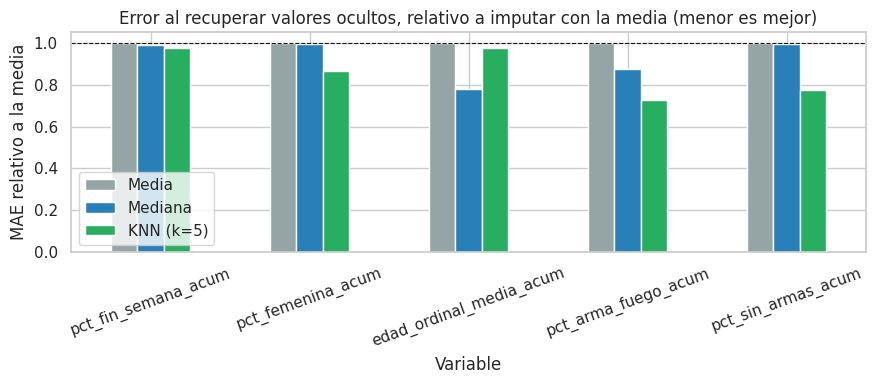

In [25]:
mejor = zanahoria_2026_df_imp_rel.loc["PROMEDIO RELATIVO"].idxmin()
print("Método con menor error relativo de recuperación:", mejor)
ax = zanahoria_2026_df_imp_rel.drop(index="PROMEDIO RELATIVO").plot.bar(figsize=(9, 4), rot=20, color=["#95a5a6", "#2980b9", "#27ae60"])
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set(title="Error al recuperar valores ocultos, relativo a imputar con la media (menor es mejor)", ylabel="MAE relativo a la media", xlabel="Variable")
plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "zanahoria_2026_imputacion_mae.png", dpi=130)
plt.show()

**Resultado y decisión: KNN (k = 5).** La media es la peor opción casi siempre: la cola de municipios
grandes la arrastra. Entre mediana y KNN, **KNN gana en 4 de las 5 variables** (femenina, arma de fuego,
sin armas y, por poco, fin de semana) y recupera hasta 27 % mejor que la media en los porcentajes de
armas; la mediana solo gana en `edad_ordinal_media_acum`, una variable que casi no varía (casi todo es
"adultos"). Promediando el error relativo, KNN queda primero. Tiene sentido: un municipio sin historial
se parece más a otros municipios de actividad similar que a un "municipio promedio". Las 2 043 filas con
nulo corresponden a municipios sin casos previos y la bandera `sin_historial_previo` le avisa al modelo
que ese perfil es un valor estimado.

### 6.3 Escalado: ¿Min-Max, Z-score o RobustScaler?
Se comparan los tres sobre una variable que, **incluso después del log**, conserva extremos.

In [26]:
col_demo = "casos_lag1_log"
demo = zanahoria_2026_df_trans.loc[entrena, [col_demo]]
comparacion = pd.DataFrame({
    "original (log)": demo[col_demo],
    "Min-Max": MinMaxScaler().fit_transform(demo).ravel(),
    "Z-score": StandardScaler().fit_transform(demo).ravel(),
    "Robust": RobustScaler().fit_transform(demo).ravel(),
}).describe().loc[["mean", "std", "min", "25%", "50%", "75%", "max"]]
comparacion

,original (log),Min-Max,Z-score,Robust
mean,1.194,0.121,-0.000,0.257
std,1.331,0.135,1.000,0.684
min,0.000,0.000,-0.897,-0.356
25%,0.000,0.000,-0.897,-0.356
50%,0.693,0.071,-0.376,0.000
75%,1.946,0.198,0.565,0.644
max,9.829,1.000,6.486,4.695


**Decisión: `RobustScaler`.** Resta la mediana y divide por el IQR, así que los municipios grandes
(que se conservaron a propósito) no comprimen al resto en un rango diminuto como ocurre con Min-Max,
ni inflan la media y la desviación como ocurre con Z-score. Solo se escalan las columnas numéricas;
las dummies (0/1) y el objetivo no se escalan.

### 6.4 Aplicación final: escalado + imputación KNN, ajustados con **entrenamiento**

In [27]:
imputador_final = KNNImputer(n_neighbors=5) if mejor.startswith("KNN") else SimpleImputer(strategy={"Media": "mean", "Mediana": "median"}[mejor])
imputador_final.fit(X_tr)                       # se aprende solo con filas de entrenamiento

X_todo = pd.DataFrame(escalador.transform(zanahoria_2026_df_trans[cols_num]), columns=cols_num, index=zanahoria_2026_df_trans.index)
X_todo = pd.DataFrame(imputador_final.transform(X_todo), columns=cols_num, index=zanahoria_2026_df_trans.index)
assert X_todo.isna().sum().sum() == 0, "quedaron nulos"
print("Nulos tras imputar:", int(X_todo.isna().sum().sum()), "| método:", mejor)
# Las columnas del parquet quedan en escala RobustScaler; la mediana/IQR provienen únicamente de entrenamiento

Nulos tras imputar: 0 | método: KNN (k=5)


## 7. Codificación de variables categóricas
* **One-Hot (`drop_first=True`)** para variables **nominales** sin orden: `departamento` (32 niveles) y
  `perfil_dominante_lag1` (hurto / VIF / homicidio / otros / sin casos). `drop_first` elimina una categoría
  redundante y evita colinealidad perfecta en la regresión lineal.
* **Ordinal** para la edad de la víctima (ya codificada en 2.2, y llega al panel como `edad_ordinal_media_acum`).

In [28]:
dummies = pd.get_dummies(
    zanahoria_2026_df_trans[["departamento", "perfil_dominante_lag1"]],
    prefix=["dep", "perfil"], drop_first=True, dtype="int8",
)
print(f"Columnas One-Hot: {dummies.shape[1]}  (departamento: {dummies.filter(like='dep_').shape[1]}, perfil: {dummies.filter(like='perfil_').shape[1]})")
dummies.columns = [c.replace(" ", "_").replace(".", "") for c in dummies.columns]

Columnas One-Hot: 35  (departamento: 31, perfil: 4)


## 8. Ensamblado y guardado de `datos_limpios.parquet`

In [29]:
zanahoria_2026_df_limpio = pd.concat(
    [
        zanahoria_2026_df_trans[["dane", "departamento", "municipio", "mes", "particion", "atipico_iqr", "sin_historial_previo", "casos", "y_log1p"]],
        # casos del mes anterior SIN transformar: solo para construir la regla ingenua de comparación en la Fase C (no es variable del modelo)
        zanahoria_2026_df_feat[["casos_lag1"]].rename(columns={"casos_lag1": "casos_lag1_ref"}).astype("int64"),
        X_todo,
        dummies,
    ],
    axis=1,
)
zanahoria_2026_df_limpio["dane"] = zanahoria_2026_df_limpio["dane"].astype("int64")
assert zanahoria_2026_df_limpio.isna().sum().sum() == 0, "el parquet no debe tener nulos"

ruta_parquet = CARPETA_ENTREGA / "datos_limpios.parquet"
zanahoria_2026_df_limpio.to_parquet(ruta_parquet, index=False)
print(f"Guardado: {ruta_parquet.name}  ->  {zanahoria_2026_df_limpio.shape[0]:,} filas x {zanahoria_2026_df_limpio.shape[1]} columnas")
zanahoria_2026_df_limpio.head(3)

Guardado: datos_limpios.parquet  ->  16,500 filas x 59 columnas


,dane,departamento,municipio,mes,particion,atipico_iqr,sin_historial_previo,casos,y_log1p,casos_lag1_ref,...,dep_SANTANDER,dep_SUCRE,dep_TOLIMA,dep_VALLE,dep_VAUPÉS,dep_VICHADA,perfil_HURTO,perfil_OTROS,perfil_SIN_CASOS,perfil_VIF
0,5001000,ANTIOQUIA,MEDELLÍN,2,test,1,0,2743,7.917,2613,...,0,0,0,0,0,0,1,0,0,0
1,5001000,ANTIOQUIA,MEDELLÍN,3,train,1,0,3222,8.078,2743,...,0,0,0,0,0,0,1,0,0,0
2,5001000,ANTIOQUIA,MEDELLÍN,4,train,1,0,2786,7.933,3222,...,0,0,0,0,0,0,1,0,0,0


### 8.1 Perfil anual por municipio (insumo del clustering de la Fase C)
El clustering no predice nada, así que no necesita partición. Se guarda el perfil de cada municipio
(una fila por código DANE) **sin escalar**; el escalado del clustering se hace en la Fase C.

In [30]:
zanahoria_2026_df_perfil = construir_perfil_municipios(zanahoria_2026_panel)
zanahoria_2026_df_perfil.to_parquet(CARPETA_DATOS / "perfil_municipios.parquet", index=False)
print("perfil_municipios.parquet:", zanahoria_2026_df_perfil.shape)

perfil_municipios.parquet: (1500, 18)


## 9. Resumen del pipeline y verificación final

In [31]:
resumen = pd.Series({
    "Casos crudos leídos": len(zanahoria_2026_df_crudo),
    "Filas de pie eliminadas": int(es_pie.sum()),
    "Casos limpios": len(zanahoria_2026_df_casos),
    "Filas idénticas conservadas": int(n_dup),
    "Panel municipio-mes (feb-dic)": len(zanahoria_2026_df_limpio),
    "Filas train": int((zanahoria_2026_df_limpio["particion"] == "train").sum()),
    "Filas test": int((zanahoria_2026_df_limpio["particion"] == "test").sum()),
    "Columnas numéricas escaladas": len(cols_num),
    "Columnas One-Hot": dummies.shape[1],
}, name="valor")
resumen.to_frame()

,valor
Casos crudos leídos,480131
Filas de pie eliminadas,40
Casos limpios,480091
Filas idénticas conservadas,301560
Panel municipio-mes (feb-dic),16500
Filas train,13200
Filas test,3300
Columnas numéricas escaladas,14
Columnas One-Hot,35


## 10. Decisiones y justificación (resumen para el documento de la fase)

| Paso | Decisión | Por qué |
|---|---|---|
| Filas de pie de página | Eliminar (40) | No son casos: no tienen código DANE |
| Duplicados | **Conservar** las 301 560 filas idénticas | La fuente no trae ID de caso; `CANTIDAD` = 1 siempre, así que cada fila es un caso real (el panel suma exactamente 480 091, igual que el Proyecto 1) |
| Texto | MAYÚSCULAS, sin `(CT)`, llave = código DANE | 291 nombres aparecen con varios códigos (centros poblados del mismo municipio, p. ej. Valledupar con 15, y homónimos entre departamentos); el nombre no identifica |
| Armas raras (< 0.1 %) | Agrupar en `OTRO` | 13 categorías casi vacías no aportan señal y inflarían las columnas |
| `NO REPORTADO` en armas | Conservar como categoría | El 60 % de los homicidios de tránsito no involucra arma; imputar la moda inventaría "sin empleo de armas" |
| Nulos de género/edad **puntuales** | **Moda por tipo de delito** | Son variables categóricas; la moda global asignaría género masculino en violencia intrafamiliar |
| Nulos de género/edad **estructurales** | No imputar | Terrorismo y Piratería nunca registran víctima |
| Nulos numéricos (porcentajes sin historial) | **KNN (k=5)** ajustado en entrenamiento + bandera | Gana en 4 de 5 variables y en error relativo promedio frente a media y mediana (experimento con valores ocultos) |
| Atípicos | **Conservar**, mitigar con `log1p` y `RobustScaler` | Son capitales reales (Bogotá 18 567 casos/mes); borrarlos eliminaría el fenómeno que se quiere predecir |
| Asimetría | `log1p` en 7 conteos (asimetría > 1) | Hay ceros reales: Box-Cox no los admite; `log1p` es reversible e interpretable |
| Nominales (departamento, perfil dominante) | **One-Hot, `drop_first=True`** | Sin orden natural; `drop_first` evita colinealidad en la regresión lineal |
| Edad de la víctima | **Ordinal** (menores < adolescentes < adultos) | Tiene orden natural |
| Escalado | `RobustScaler`, ajustado solo en entrenamiento | Resistente a los municipios grandes que se conservaron |
| Fuga de información | Partición 80/20 **antes** de ajustar nada | El enunciado lo exige; verificado con aserciones |

**Limitación a tener presente:** `casos_otros_lag1` (secuestro + terrorismo) y otras columnas casi siempre
en cero conservan asimetría tras el log; ninguna transformación monótona corrige una variable que vale 0 en
más del 95 % de las filas, por eso se confía en el escalador robusto.